# Variational Quantum Eigensolver for Four Coupled Transmons

Follow the four implementation steps in VQE_Coupled_Transmon.ipynb and Section 3 of the original vqe.ipynb. Coursework_1.ipynb supplies the commenting style.

| Procedure | Implementation |
|---|---|
| 3.1 Step 1 | Build and Pauli-decompose the charge model, project local levels, benchmark, and build the ansatz. |
| 3.2 Step 2 | Define a target, transpile, and apply its layout to the observable. |
| 3.3 Step 3 | Define the cost, initialize angles, and run COBYLA. |
| 3.4 Step 4 | Validate in charge coordinates, report errors, test the cutoff, and plot convergence. |

**Assumptions and deviations**

- Number the drawn transmons 1 top-left, 2 bottom-left, 3 bottom-right, 4 top-right. Use effective charge couplings around this square. All numerical parameters are illustrative.
- The images show CPW interconnects. Static couplings approximate their effect here. Extracted capacitances, Josephson parameters, and resonator data are needed to predict the pictured device. The relationship between the visible 8 nH components and Josephson inductances must be confirmed before deriving $E_J$.
- Use zero offset charges and $N=5$ on every island. The full charge benchmark has $11^4=14\,641$ states. Its direct 16-qubit Pauli encoding is built and checked sparsely.
- VQE retains four local eigenlevels per transmon and encodes even total parity on seven qubits, with no unused basis states. The cost uses this projected Hamiltonian.
- SciPy eigsh replaces dense NumPy diagonalization of the large charge matrix. NumPy diagonalizes the projected matrix.
- A 34-angle real circuit and perturbative initialization replace the previous seven-angle ansatz. Its remaining variational error is reported.
- Keep the local noiseless Estimator and seeded COBYLA. The elapsed-time calculation uses seconds directly, correcting the extra $10^{-9}$ multiplier in the attached notebook.

The first code cell imports the tested libraries. The second defines runnable parameters.


In [1]:
# %pip install qiskit==2.2.3 numpy==2.3.4 scipy==1.16.3 matplotlib==3.10.7
# Tested with Python 3.14.0 and the versions above.
from time import perf_counter
import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sp
from scipy.optimize import minimize
from scipy.sparse.linalg import eigsh
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.primitives import StatevectorEstimator
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.quantum_info import Operator, SparsePauliOp, Statevector
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

In [2]:
E_C = np.array([0.25, 0.24, 0.26, 0.25])  # Charging energies / h [GHz].
E_J = np.array([12.50, 13.20, 12.00, 13.70])  # Josephson energies / h [GHz].
N = 5  # Charge cutoff per island [integer Cooper-pair number].
# Offset charges are fixed at zero for the parity encoding.
edges = [(0, 1, 0.10), (1, 2, 0.10), (2, 3, 0.10), (3, 0, 0.10)]
# Each zero-based edge coefficient multiplies n_i * n_j [GHz].
seed = 42
max_evals = 1500
initial_radius = 0.005  # Initial COBYLA trust-region radius [radians].
optimizer_tol = 1e-7   # Final COBYLA trust-region radius [radians].
assert isinstance(N, int) and N >= 2
assert E_C.shape == E_J.shape == (4,)
assert np.all(np.isfinite(E_C)) and np.all(E_C > 0)
assert np.all(np.isfinite(E_J)) and np.all(E_J > 0)
assert all(0 <= i < 4 and 0 <= j < 4 and i != j and np.isfinite(g)
           for i, j, g in edges)
K = np.diag(4 * E_C)  # Charging quadratic form [GHz].
for i, j, g in edges:
    K[i, j] += g / 2
    K[j, i] += g / 2
assert np.linalg.eigvalsh(K)[0] > 0
print("E_J / E_C =", E_J / E_C)

E_J / E_C = [50.         55.         46.15384615 54.8       ]


### 3.1 Step 1: Map the problem to quantum circuits and operators

All energies below are divided by $h$ and expressed in GHz. At zero offset charge,

$$H=\sum_{i=1}^{4}\left(4E_{Ci}\hat n_i^2-E_{Ji}\cos\hat\phi_i\right)
+\sum_{(i,j)\in\mathcal E}g_{ij}\hat n_i\hat n_j.$$

Charging and charge coupling are diagonal. The Josephson term moves one Cooper pair on its island and produces neighbouring matrix elements $-E_{Ji}/2$. The effective couplings require validation against circuit extraction for a device prediction. [Superconducting Circuit Companion](https://doi.org/10.1103/PRXQuantum.2.040204)

Sparse tensor products keep transmon 1 as the least-significant factor. Expect a $14\,641\times14\,641$ sparse charge matrix.

In [3]:
def local_hamiltonian(E_Ci, E_Ji, cutoff):
    """Return a zero-offset charge Hamiltonian [GHz] and charge operator."""
    n = np.arange(-cutoff, cutoff + 1)  # Charge / (2e) [dimensionless].
    hopping = np.full(n.size - 1, -E_Ji / 2)  # Tunnelling elements [GHz].
    h = sp.diags(
        [hopping, 4 * E_Ci * n**2, hopping], [-1, 0, 1], format="csr"
    )
    return h, sp.diags(n, format="csr")


def tensor_sparse(operators):
    """Tensor operators with site 0 as the least-significant factor."""
    result = sp.csr_matrix([[1.0]])
    for operator in reversed(operators):
        result = sp.kron(result, operator, format="csr")
    return result


def build_hamiltonian(local_h, local_q):
    """Assemble local energies and the selected charge couplings [GHz]."""
    size = local_h[0].shape[0]
    identity = sp.eye(size, format="csr")
    result = sp.csr_matrix((size**4, size**4))
    for site, h in enumerate(local_h):
        operators = [identity] * 4
        operators[site] = h
        result += tensor_sparse(operators)
    for i, j, g in edges:
        operators = [identity] * 4
        operators[i], operators[j] = local_q[i], local_q[j]
        result += g * tensor_sparse(operators)
    return result


local_h, local_q = [], []
for ec, ej in zip(E_C, E_J):
    h, charge = local_hamiltonian(ec, ej, N)
    local_h.append(h)
    local_q.append(charge)
H = build_hamiltonian(local_h, local_q)
print(f"Physical charge Hamiltonian: {H.shape}, {H.nnz:,} stored entries")

Physical charge Hamiltonian: (14641, 14641), 121,120 stored entries


/var/folders/p2/8f_j61vd7kg1r480z7y2zqvw0000gn/T/ipykernel_98116/4152350657.py:8: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  return h, sp.diags(n, format="csr")


#### Charge encoding and Pauli reconstruction

Each island uses four charge qubits for eleven physical states. Zero the padded charge operator and assign a positive local padding energy that exceeds a bound on all negative Josephson and coupling energies. Every sector containing padding then lies above zero. The all-zero-charge physical state has zero expectation, so padding cannot be the ground state.

Decompose the small local matrices and combine their Pauli strings. Check the resulting full 16-qubit observable against the sparse embedded matrix. Expect 973 Pauli terms.

In [4]:
def tensor_pauli(operators):
    """Tensor Paulis with the same ordering as the sparse matrices."""
    result = operators[-1]
    for operator in reversed(operators[:-1]):
        result = result ^ operator
    return result


d = 2 * N + 1
charge_qubits = int(d - 1).bit_length()
D = 2**charge_qubits
E_pad = float(E_J.sum() + sum(abs(g) * N**2 for _, _, g in edges) + 1.0)
# E_pad [GHz] exceeds a bound on all negative local and coupling energies.
padded_h, padded_q = [], []
for h, charge in zip(local_h, local_q):
    h_pad = E_pad * np.eye(D)
    h_pad[:d, :d] = h.toarray()
    q_pad = np.zeros((D, D))
    q_pad[:d, :d] = charge.toarray()
    padded_h.append(sp.csr_matrix(h_pad))
    padded_q.append(sp.csr_matrix(q_pad))

identity_pauli = SparsePauliOp("I" * charge_qubits)
embedded_h, embedded_q = [], []
for site in range(4):
    for matrices, destination in ((padded_h, embedded_h), (padded_q, embedded_q)):
        operators = [identity_pauli] * 4
        operators[site] = SparsePauliOp.from_operator(
            Operator(matrices[site].toarray()), atol=1e-12, rtol=0
        )
        destination.append(tensor_pauli(operators))
hamiltonian_charge = sum(embedded_h)
for i, j, g in edges:
    hamiltonian_charge += g * (embedded_q[i] @ embedded_q[j])
hamiltonian_charge = hamiltonian_charge.simplify(atol=1e-12)
A_charge = build_hamiltonian(padded_h, padded_q)
difference = (hamiltonian_charge.to_matrix(sparse=True) - A_charge).tocsr()
assert np.max(np.abs(difference.data), initial=0.0) < 1e-9
print(f"Charge Pauli reconstruction passed ({len(hamiltonian_charge)} terms).")

Charge Pauli reconstruction passed (973 terms).


#### Project local levels and encode total parity

Retain four eigenlevels per isolated transmon and project $Q_i$ as $V_i^\mathsf{T}Q_iV_i$. This gives a 256-dimensional level Hamiltonian. The code checks that local levels alternate charge-reflection parity.

At zero offset charge, the ground state has even total parity. Its 128 level configurations fit exactly on seven qubits. In the original eight level bits, bits 0, 2, 4 and 6 give local parity. Drop bit 6 and recover it from the other three parity bits. Expect a seven-qubit VQE matrix and a successful Pauli reconstruction check.

In [5]:
local_e, local_v, level_q = [], [], []
for h, charge in zip(local_h, local_q):
    values, vectors = np.linalg.eigh(h.toarray())
    vectors = vectors[:, :4]
    assert np.allclose(
        vectors[::-1], vectors * np.array([1, -1, 1, -1]),
        atol=1e-9, rtol=0,
    )
    local_e.append(values[:4])
    local_v.append(vectors)
    level_q.append(sp.csr_matrix(vectors.T @ charge @ vectors))
H_level = build_hamiltonian([sp.diags(e) for e in local_e], level_q).toarray()

# Keep level bits 0..5 and 7. Compute bit 6 from the other parity bits.
encoded = np.arange(128)
last_parity = ((encoded >> 0) ^ (encoded >> 2) ^ (encoded >> 4)) & 1
physical_levels = (encoded & 63) | ((encoded & 64) << 1) | (last_parity << 6)
A = H_level[np.ix_(physical_levels, physical_levels)]
num_qubits = 7
hamiltonian = SparsePauliOp.from_operator(Operator(A), atol=1e-11, rtol=0)
assert np.allclose(hamiltonian.to_matrix(), A, atol=1e-9, rtol=0)
print(f"VQE encoding: {num_qubits} qubits, {len(hamiltonian)} Pauli terms")

VQE encoding: 7 qubits, 77 Pauli terms


#### Exact reference energies

Use eigsh for the full charge ground energy, with an eigenpair residual check. Use NumPy for the projected minimum, and verify that even parity contains the projected ground state. These references are used for validation. Expect both energies near $-41.530176$ GHz. [SciPy eigsh documentation](https://docs.scipy.org/doc/scipy-1.16.1/reference/generated/scipy.sparse.linalg.eigsh.html)

In [6]:
values, vectors = eigsh(
    H, k=1, which="SA", tol=1e-11,
    v0=np.random.default_rng(seed).normal(size=H.shape[0]),
)
E_exact = float(values[0])  # Full charge reference [GHz].
reference_residual = np.linalg.norm(H @ vectors[:, 0] - E_exact * vectors[:, 0])
assert reference_residual < 1e-7  # Absolute eigenpair residual [GHz].
E_projected = float(np.linalg.eigvalsh(A)[0])  # Four-level reference [GHz].
assert np.isclose(np.linalg.eigvalsh(H_level)[0], E_projected, atol=1e-9, rtol=0)
assert E_projected >= E_exact - 1e-9
print(f"Charge ground energy:    {E_exact:.12f} GHz")
print(f"Projected ground energy: {E_projected:.12f} GHz")
print(f"Reference residual:      {reference_residual:.3e} GHz")

Charge ground energy:    -41.530176421407 GHz
Projected ground energy: -41.530176305133 GHz
Reference residual:      2.621e-10 GHz


#### Ansatz

Zero angles prepare the product of isolated ground states. Use a rotation for each encoded configuration involving one or two locally excited transmons. Products of gates can populate configurations with more excited sites.

Each generator has one $Y$ and otherwise $X$ or $I$, making $e^{-i\theta P/2}$ real. The circuit is restricted, and its residual is measured against the projected minimum. Expect 34 angles. Evolution of a single Pauli string needs no product-formula approximation. [Qiskit PauliEvolutionGate documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.2/qiskit.circuit.library.PauliEvolutionGate)

In [7]:
level_labels = np.array([
    [(index >> (2 * site)) & 3 for site in range(4)]
    for index in physical_levels
])
masks = [
    index for index in range(1, 128)
    if np.count_nonzero(level_labels[index]) <= 2
]
theta = ParameterVector("theta", len(masks))  # Gate angles [radians].
ansatz = QuantumCircuit(num_qubits)
for parameter, mask in zip(theta, masks):
    bits = [bit for bit in range(num_qubits) if mask & (1 << bit)]
    label = ["I"] * num_qubits
    for bit in bits:
        label[num_qubits - 1 - bit] = "X"
    label[num_qubits - 1 - bits[0]] = "Y"
    generator = SparsePauliOp("".join(label))
    ansatz.append(PauliEvolutionGate(generator, time=parameter / 2), range(num_qubits))
num_params = ansatz.num_parameters
print(f"Ansatz parameters: {num_params}")

Ansatz parameters: 34


### 3.2 Step 2: Optimize for target hardware

Use the previous notebook's local all-to-all target with u and cx gates. Expect seven target qubits. The simulated processor connectivity is independent of the physical ring being modeled.

In [8]:
backend = GenericBackendV2(
    num_qubits=num_qubits, basis_gates=["u", "cx"], seed=seed, noise_info=False
)
target = backend.target
print(f"Local target: {target.num_qubits} qubits")

Local target: 7 qubits


#### Transpile the ansatz

Compile once before optimization. Expect circuit depth and gate counts.

In [9]:
pm = generate_preset_pass_manager(
    target=target, optimization_level=3, seed_transpiler=seed
)
ansatz_isa = pm.run(ansatz)
assert set(ansatz_isa.parameters) == set(ansatz.parameters)
print(f"Transpiled depth: {ansatz_isa.depth()}")
print(f"Gate counts: {dict(ansatz_isa.count_ops())}")

Transpiled depth: 98
Gate counts: {'u': 81, 'cx': 71}


#### Apply the layout to the Hamiltonian

Map the projected Pauli observable to the circuit's final wires. Expect the logical-to-final qubit mapping.

In [10]:
hamiltonian_isa = hamiltonian.apply_layout(ansatz_isa.layout)
assert hamiltonian_isa.num_qubits == ansatz_isa.num_qubits
print("Logical-to-final qubits:", ansatz_isa.layout.final_index_layout())

Logical-to-final qubits: [5, 0, 3, 4, 1, 6, 2]


### 3.3 Step 3: Execute on target hardware

#### 3.3.1 Reporting out values

Record noiseless projected energies and callback iterations separately. The next cell defines the functions and histories with no printed output. [Qiskit StatevectorEstimator documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.2/qiskit.primitives.StatevectorEstimator)

In [11]:
def cost_func(params, ansatz, hamiltonian, estimator):
    """Return and record one projected energy expectation [GHz]."""
    pub = (ansatz, hamiltonian, params)
    energy = float(estimator.run([pub]).result()[0].data.evs.item())
    cost_history_dict["cost_history"].append(energy)
    return energy


def record_iteration(intermediate_result):
    """Record the optimizer's reported iteration energy [GHz]."""
    cost_history_dict["iters"].append(intermediate_result.nit)
    cost_history_dict["iteration_energy"].append(float(intermediate_result.fun))


cost_history_dict = {"cost_history": [], "iters": [], "iteration_energy": []}

#### Initial parameters

First-order weak-coupling amplitudes are approximately $a_k=-A_{k0}/(A_{kk}-A_{00})$. Each selected Pauli rotation initially creates amplitude $\theta_k/2$. Set $\theta_k\approx2a_k$ and add tiny seeded perturbations. This uses matrix elements without using a coupled ground eigenvector. Expect 34 initial angles.

In [12]:
gaps = np.diag(A)[masks] - A[0, 0]  # Reference excitation costs [GHz].
assert np.all(gaps > 0)
rng = np.random.default_rng(seed)
x0 = -2 * A[masks, 0] / gaps  # First-order rotation angles [radians].
x0 += rng.normal(0.0, 1e-5, num_params)
print(f"Initialized {x0.size} angles from weak-coupling amplitudes.")

Initialized 34 angles from weak-coupling amplitudes.


#### Run the classical optimizer

COBYLA updates the angles using Estimator energies. The maxiter option caps evaluations in the pinned SciPy version. Time the optimization in seconds. The execution cell stores the result, and the following cell prints its status and elapsed time.

In [13]:
for history in cost_history_dict.values():
    history.clear()
estimator = StatevectorEstimator(default_precision=0.0, seed=seed)
start = perf_counter()
res = minimize(
    cost_func, x0, args=(ansatz_isa, hamiltonian_isa, estimator),
    method="COBYLA", callback=record_iteration,
    options={"maxiter": max_evals, "rhobeg": initial_radius, "tol": optimizer_tol},
)
elapsed = perf_counter() - start  # Optimization wall time [seconds].

In [14]:
print(res)
print(f"Optimization elapsed time: {elapsed:.3f} s")

 message: Return from COBYLA because the trust region radius reaches its lower bound.
 success: True
  status: 0
     fun: -41.530172584925126
       x: [-2.501e-02  9.246e-04 ...  3.039e-04 -1.205e-05]
    nfev: 958
   maxcv: 0.0
Optimization elapsed time: 6.929 s


### 3.4 Step 4: Post-process results

Decode the trial state and apply the local eigenvector matrices to reconstruct its physical charge amplitudes. Check that the full charge expectation matches the transpiled Estimator result.

Report local-level projection error, the remaining circuit and optimization gap, and total error against the charge reference. Expect a total VQE error of a few kHz.

In [15]:
assert len(cost_history_dict["cost_history"]) == res.nfev
E_vqe = float(res.fun)  # [GHz].
params_opt = dict(zip(ansatz_isa.parameters, res.x))
psi_encoded = Statevector.from_instruction(ansatz.decompose().assign_parameters(params_opt)).data
E_logical = float(np.vdot(psi_encoded, A @ psi_encoded).real)
assert np.isclose(E_logical, E_vqe, atol=1e-9, rtol=0)

# Decode the 128 amplitudes into the four local-level registers.
psi_level = np.zeros(256, dtype=complex)
psi_level[physical_levels] = psi_encoded
psi_charge = psi_level.reshape((4,) * 4)
for site, basis in enumerate(local_v):
    axis = 3 - site
    psi_charge = np.tensordot(basis, psi_charge, axes=(1, axis))
    psi_charge = np.moveaxis(psi_charge, 0, axis)
psi_charge = psi_charge.ravel()
assert np.isclose(np.vdot(psi_charge, psi_charge).real, 1.0, atol=1e-10)
E_charge_trial = float(np.vdot(psi_charge, H @ psi_charge).real)
assert np.isclose(E_charge_trial, E_vqe, atol=1e-9, rtol=0)
assert E_vqe >= E_projected - 1e-9

absolute_error = abs(E_vqe - E_exact)  # [GHz].
E_uncoupled = float(sum(e[0] for e in local_e))  # [GHz].
print(f"Exact charge energy:     {E_exact:.12f} GHz")
print(f"Projected minimum:       {E_projected:.12f} GHz")
print(f"VQE energy:              {E_vqe:.12f} GHz")
print(f"Absolute error:          {absolute_error:.3e} GHz")
print(f"Local-level projection:  {1e6 * (E_projected - E_exact):.3f} kHz")
print(f"Remaining VQE gap:       {1e6 * (E_vqe - E_projected):.3f} kHz")
print(f"Coupling energy shift:   {1000 * (E_exact - E_uncoupled):.6f} MHz")

Exact charge energy:     -41.530176421407 GHz
Projected minimum:       -41.530176305133 GHz
VQE energy:              -41.530172584925 GHz
Absolute error:          3.836e-06 GHz
Local-level projection:  0.116 kHz
Remaining VQE gap:       3.720 kHz
Coupling energy shift:   -6.025431 MHz


#### Check charge truncation

Repeat the sparse charge reference at $N+2$, keeping the circuit coefficients fixed. This tests charge truncation independently of VQE. Expect the enlarged basis to lower the ground energy.

In [16]:
larger_h, larger_q = [], []
for ec, ej in zip(E_C, E_J):
    h, charge = local_hamiltonian(ec, ej, N + 2)
    larger_h.append(h)
    larger_q.append(charge)
H_larger = build_hamiltonian(larger_h, larger_q)
values_larger, vectors_larger = eigsh(
    H_larger, k=1, which="SA", tol=1e-11,
    v0=np.random.default_rng(seed).normal(size=H_larger.shape[0]),
)
E_larger = float(values_larger[0])  # [GHz].
larger_residual = np.linalg.norm(
    H_larger @ vectors_larger[:, 0] - E_larger * vectors_larger[:, 0]
)
assert larger_residual < 1e-7
assert E_larger <= E_exact + 1e-9
print(f"Charge energy at N={N + 2}: {E_larger:.12f} GHz")
print(f"Cutoff energy change: {1e6 * (E_larger - E_exact):.3f} kHz")

Charge energy at N=7: -41.530330974026 GHz
Cutoff energy change: -154.553 kHz


/var/folders/p2/8f_j61vd7kg1r480z7y2zqvw0000gn/T/ipykernel_98116/4152350657.py:8: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  return h, sp.diags(n, format="csr")


#### Convergence plot

Plot callback energies against optimizer iteration, with horizontal lines for the charge reference and projected minimum. Expect the curves to approach closely at this scale.

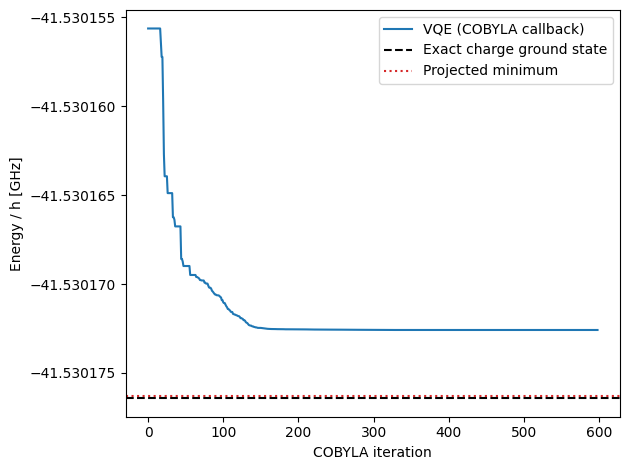

In [17]:
fig, ax = plt.subplots()
ax.plot(
    cost_history_dict["iters"], cost_history_dict["iteration_energy"],
    label="VQE (COBYLA callback)",
)
ax.axhline(E_exact, color="black", linestyle="--", label="Exact charge ground state")
ax.axhline(E_projected, color="tab:red", linestyle=":", label="Projected minimum")
ax.set_xlabel("COBYLA iteration")
ax.set_ylabel("Energy / h [GHz]")
ax.ticklabel_format(axis="y", style="plain", useOffset=False)
ax.legend()
fig.tight_layout()
plt.show()

## Results and limitations

With the tested defaults, COBYLA converged in 958 evaluations.

| Quantity | Tested result |
|---|---:|
| Full charge ground energy divided by $h$ | $-41.530176421407$ GHz |
| Four-level projected minimum divided by $h$ | $-41.530176305133$ GHz |
| VQE energy divided by $h$ | $-41.530172584925$ GHz |
| Absolute VQE error | $3.836$ kHz |
| Local-level projection error | $0.116$ kHz |
| Remaining circuit and optimization gap | $3.720$ kHz |
| Charge energy shift from $N=5$ to $N=7$ | $-154.553$ kHz |

The remaining VQE gap includes the ansatz restriction and optimizer termination. The cutoff check tests a separate approximation. VQE uses seven parity-encoded qubits with no padding, and the reconstructed trial has support only on physical charge states. The direct 16-qubit charge encoding has its padding and Pauli decomposition checked separately.

The parameters describe an illustrative effective ring model. Device predictions require extracted circuit parameters and validation of the CPW-coupler treatment. The parity encoding assumes zero offset charges. Stronger coupling can require more local levels or a larger ansatz. The local Estimator includes no gate or shot noise. The compiled trial circuit used 71 CX gates in the tested run.
